In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import seaborn as sns
sns.set_theme(style='whitegrid', font_scale=2, palette=sns.color_palette(),)
import matplotlib.pyplot as plt
import duckdb
import polars as pl

In [3]:
duckdb.sql("""
attach '../runs.sqlite';
use runs;
""")

# Dynamical system

### Lorenz '63

In [4]:
dataset_rows = duckdb.sql("""
select
    *
from Dataset
join DynamicalSystem on Dataset.id = DynamicalSystem.id
join Lorenz63 on DynamicalSystem.id = Lorenz63.id
where true
and batch_count_train = 0
and batch_count_val = 0
and batch_count_test = 0
and time_step_count = 90
""")
dataset_rows.show(max_width=120)
assert len(dataset_rows) == 1

┌────────────┬───────────────────┬─────────────────┬──────────────────┬───┬────────────────────┬───────────┬───────┐
│ batch_size │ batch_count_train │ batch_count_val │ batch_count_test │ … │        beta        │ rescaling │  id   │
│   int64    │       int64       │      int64      │      int64       │   │       double       │  double   │ int64 │
├────────────┼───────────────────┼─────────────────┼──────────────────┼───┼────────────────────┼───────────┼───────┤
│        500 │                 0 │               0 │                0 │ … │ 2.6666666666666665 │      20.0 │     4 │
├────────────┴───────────────────┴─────────────────┴──────────────────┴───┴────────────────────┴───────────┴───────┤
│ 1 rows                                                                                      16 columns (7 shown) │
└──────────────────────────────────────────────────────────────────────────────────────────────────────────────────┘



### FitzHugh-Nagumo

In [ ]:
dataset_rows = duckdb.sql("""
select
    *
from Dataset
join DynamicalSystem on Dataset.id = DynamicalSystem.id
join FitzHughNagumo on DynamicalSystem.id = FitzHughNagumo.id
where true
and batch_count_train = 0
and batch_count_val = 0
and batch_count_test = 0
and time_step_count = 310
""")
dataset_rows.show(max_width=120)
assert len(dataset_rows) == 1

# Model

### Probability path

##### Conditional optimal transport

In [ ]:
probability_path_rows = duckdb.sql("""
select
    *
from ProbabilityPath
join ConditionalOT on ProbabilityPath.id = ConditionalOT.id
""")
probability_path_rows.show()
assert len(probability_path_rows) == 1

##### Variance exploding

In [5]:
probability_path_rows = duckdb.sql("""
select
    *
from ProbabilityPath
join VarianceExploding on ProbabilityPath.id = VarianceExploding.id
""")
probability_path_rows.show()
assert len(probability_path_rows) == 1

┌───────────────────┬───────┬──────────┬───────────┬───────────┬────────────────────────┬───────┐
│  sa_inheritance   │  id   │ time_min │ sigma_min │ sigma_max │ finzi_karras_weighting │  id   │
│      varchar      │ int64 │  double  │  double   │  double   │         int64          │ int64 │
├───────────────────┼───────┼──────────┼───────────┼───────────┼────────────────────────┼───────┤
│ VarianceExploding │     1 │    0.001 │     0.001 │     300.0 │                      1 │     1 │
└───────────────────┴───────┴──────────┴───────────┴───────────┴────────────────────────┴───────┘



### Steering

##### Source parallel tempering

In [ ]:
steering_metadata = dict(
    col='update_count',
    col_latex=r'$t_{\max}$',
    row='chain_count',
    row_latex='$K$',
)
steering_rows = duckdb.sql("""
select
    *
from Steering
join SourceParallelTempering on Steering.id = SourceParallelTempering.id
where true
and symmetric_binary_reward
and tilt in (select tilt from dataset_rows join SweepDynamicalSystem on dataset_rows.sa_inheritance = SweepDynamicalSystem.dynamical_system)
and chain_count in (select * from SweepSPTChainCount)
and update_count in (select * from SweepSPTUpdateCount)
""")
steering_rows.show(max_width=120)

##### Feynman-Kac

In [ ]:
steering_metadata = dict(
    col='potential',
    col_latex='Potential',
    row='ensemble_size',
    row_latex='Ensemble size',
)
steering_rows = duckdb.sql("""
select
    * exclude (potential),
    case potential
        when 'DIFFERENCE' then 'DIFF'
        else potential
    end as potential,
from Steering
join FeynmanKac on Steering.id = FeynmanKac.id
join FeynmanKacIntermediateReward on FeynmanKac.FeynmanKacIntermediateReward = FeynmanKacIntermediateReward.id
join FeynmanKacIntermediateRewardExpectedSample on FeynmanKacIntermediateReward.id = FeynmanKacIntermediateRewardExpectedSample.id
where true
and symmetric_binary_reward
and tilt in (select tilt from dataset_rows join SweepDynamicalSystem on dataset_rows.sa_inheritance = SweepDynamicalSystem.dynamical_system)
and potential in (select * from SweepFKPotential)
and ensemble_size in (select * from SweepFKEnsembleSize)
""")
steering_rows.show(max_width=120)

##### RpCN

In [6]:
steering_metadata = dict(
    col='pcn_update_count',
    col_latex=r'$M$',
    row='chain_count',
    row_latex='$K + 1$',
)
steering_rows = duckdb.sql("""
select
    *
from Steering
join RpCN on Steering.id = RpCN.id
where true
and symmetric_binary_reward
and tilt in (select tilt from dataset_rows join SweepDynamicalSystem on dataset_rows.sa_inheritance = SweepDynamicalSystem.dynamical_system)
and chain_count in (select * from SweepSPTChainCount)
and pcn_update_count in (select * from SweepSPTUpdateCount)
""")
steering_rows.show(max_width=120)

┌─────────────┬─────────────────────┬────────────────┬───┬──────────────────┬────────┬───────┬──────────────────────┐
│ batch_count │ sampling_step_count │ sa_inheritance │ … │ pcn_update_count │  tilt  │  id   │ FeynmanKacIntermed…  │
│    int64    │        int64        │    varchar     │   │      int64       │ double │ int64 │        int64         │
├─────────────┼─────────────────────┼────────────────┼───┼──────────────────┼────────┼───────┼──────────────────────┤
│          64 │                 100 │ RpCN           │ … │                1 │   8.29 │   321 │                    1 │
│          64 │                 100 │ RpCN           │ … │                2 │   8.29 │   322 │                    1 │
│          64 │                 100 │ RpCN           │ … │                4 │   8.29 │   323 │                    1 │
│          64 │                 100 │ RpCN           │ … │                8 │   8.29 │   324 │                    1 │
│          64 │                 100 │ RpCN           │ …

### Model

In [7]:
model_rows = duckdb.sql("""
select
    *
from Model
join FlowMatching on Model.id = FlowMatching.id
join probability_path_rows on FlowMatching.ProbabilityPath = probability_path_rows.id
""")
model_rows.show(max_width=120)

┌────────────────┬───────┬─────────────┬────────┬───┬──────────┬───────────┬───────────┬──────────────────────┬───────┐
│ sa_inheritance │  id   │ epoch_count │   lr   │ … │ time_min │ sigma_min │ sigma_max │ finzi_karras_weigh…  │ id_1  │
│    varchar     │ int64 │    int64    │ double │   │  double  │  double   │  double   │        int64         │ int64 │
├────────────────┼───────┼─────────────┼────────┼───┼──────────┼───────────┼───────────┼──────────────────────┼───────┤
│ FlowMatching   │     1 │        2000 │ 0.0001 │ … │    0.001 │     0.001 │     300.0 │                    1 │     1 │
├────────────────┴───────┴─────────────┴────────┴───┴──────────┴───────────┴───────────┴──────────────────────┴───────┤
│ 1 rows                                                                                         17 columns (9 shown) │
└─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┘



# Rows

In [8]:
rows = duckdb.sql("""
select
    Conf.alt_id,
    steering_rows.*,
    dataset_rows.batch_size,
from Conf
join TrainingAndEvaluation on Conf.id = TrainingAndEvaluation.id
join dataset_rows on TrainingAndEvaluation.Dataset = dataset_rows.id
join Trained on TrainingAndEvaluation.Model = Trained.id
join steering_rows on TrainingAndEvaluation.Steering = steering_rows.id
join TrainingAndEvaluation as TrainingAndEvaluation_trained on Trained.Conf = TrainingAndEvaluation_trained.id
join model_rows on TrainingAndEvaluation_trained.Model = model_rows.id
where true
and not TrainingAndEvaluation.log_constraint_values
and penalization_power = 0
-- and update_count = 8 and chain_count = 4
-- and potential = 'DIFFERENCE' and ensemble_size = 8
""")
rows.show(max_width=120)

┌──────────┬─────────────┬─────────────────────┬───┬────────┬───────┬──────────────────────┬────────────┐
│  alt_id  │ batch_count │ sampling_step_count │ … │  tilt  │ id_1  │ FeynmanKacIntermed…  │ batch_size │
│ varchar  │    int64    │        int64        │   │ double │ int64 │        int64         │   int64    │
├──────────┼─────────────┼─────────────────────┼───┼────────┼───────┼──────────────────────┼────────────┤
│ 67zrtgdg │          64 │                 100 │ … │   8.29 │   321 │                    1 │        500 │
│ ctv9lvmq │          64 │                 100 │ … │   8.29 │   322 │                    1 │        500 │
│ bbhzqg1i │          64 │                 100 │ … │   8.29 │   323 │                    1 │        500 │
│ gf2xyot7 │          64 │                 100 │ … │   8.29 │   324 │                    1 │        500 │
│ pwbk8wzz │          64 │                 100 │ … │   8.29 │   325 │                    1 │        500 │
│ xjmc3l4s │          64 │                 100

In [9]:
metrics = (
    pl.scan_csv([f'~/out/rpcn-user-defined-events/runs/{alt_id}/metrics.csv'
         for alt_id, in duckdb.sql("select alt_id from rows").fetchall()
    ], include_file_paths='file_path')
    .with_columns(alt_id=pl.col('file_path').str.split('/').list.get(-2))
    .collect()
)
metrics = duckdb.sql("""
select
    *
from rows
join metrics on rows.alt_id = metrics.alt_id
""")
metrics.show(max_width=120)

┌──────────┬─────────────┬─────────────────────┬───┬──────────────────────┬───────┬──────────────────────┬──────────┐
│  alt_id  │ batch_count │ sampling_step_count │ … │ satisfactory_sampl…  │ step  │      file_path       │  alt_id  │
│ varchar  │    int64    │        int64        │   │        double        │ int64 │       varchar        │ varchar  │
├──────────┼─────────────┼─────────────────────┼───┼──────────────────────┼───────┼──────────────────────┼──────────┤
│ pst4jh2j │          64 │                 100 │ … │                457.0 │     0 │ /home/ttransue/out…  │ pst4jh2j │
│ pst4jh2j │          64 │                 100 │ … │                468.0 │     1 │ /home/ttransue/out…  │ pst4jh2j │
│ pst4jh2j │          64 │                 100 │ … │                474.0 │     2 │ /home/ttransue/out…  │ pst4jh2j │
│ pst4jh2j │          64 │                 100 │ … │                469.0 │     3 │ /home/ttransue/out…  │ pst4jh2j │
│ pst4jh2j │          64 │                 100 │ … │    

┌─────────────┬─────────────────────┬─────────────────────┬────────────────────┬────────────────────┐
│ chain_count │          1          │          2          │         4          │         8          │
│    int64    │       double        │       double        │       double       │       double       │
├─────────────┼─────────────────────┼─────────────────────┼────────────────────┼────────────────────┤
│           2 │           0.2493125 │ 0.37818750000000007 │ 0.4908124999999999 │ 0.6043749999999999 │
│           4 │ 0.46574999999999994 │  0.5691874999999997 │ 0.7483750000000003 │ 0.8559687500000001 │
│           6 │  0.6029062499999999 │              0.6855 │ 0.8267499999999998 │         0.93103125 │
│           8 │  0.6857500000000001 │  0.7579687500000001 │ 0.8696250000000001 │ 0.9664375000000001 │
└─────────────┴─────────────────────┴─────────────────────┴────────────────────┴────────────────────┘



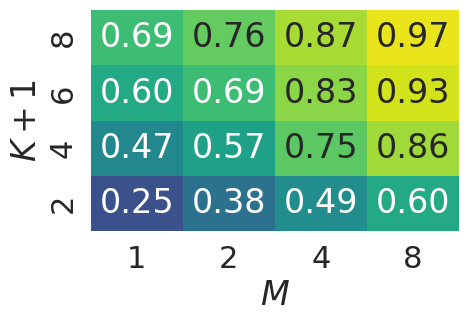

In [10]:
col, row = steering_metadata['col'], steering_metadata['row']
heatmap = duckdb.sql(f"""
select * from (
pivot (
    select
        {col},
        {row},
        satisfactory_sample_count,
        batch_count * batch_size as sample_count,
        satisfactory_sample_count / sample_count as satisfaction_rate
    from metrics
    where penalization_power = 0
) on {col}
--using sum(satisfactory_sample_count)
using sum(satisfaction_rate)
group by {row}
)
order by {row}
""")
heatmap.show()
g = (
    sns.FacetGrid(
        data=duckdb.sql("select distinct penalization_power from metrics where penalization_power = 0").pl(),
        col='penalization_power',
        height=3.7,
        aspect=1.5,
    )
    .set_titles('')
)
df = heatmap.df().set_index(row)
ax = (
    sns.heatmap(
        data=df,
        annot=True,
        fmt='.2f',
        cmap='viridis',
        vmin=0,
        vmax=1,
        ax=g.axes[0, 0],
        cbar=False,
    )
)
ax.set(xlabel=steering_metadata['col_latex'], ylabel=steering_metadata['row_latex'])
ax.invert_yaxis()
ax.get_figure().savefig('Heatmap.pdf', format='pdf', bbox_inches='tight', pad_inches=.06)